# FraudLens: Exploratory Data Analysis & Feature Investigation

This notebook explores the **Credit Card Fraud Detection** dataset (284,807 transactions, 492 frauds) to analyze class distributions, feature variance, and reconstruction patterns for the **Deep Autoencoder**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
dataset_path = Path('dataset/creditcard.csv') if Path('dataset/creditcard.csv').exists() else Path('../dataset/creditcard.csv')
df = pd.read_csv(dataset_path)
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. Class Distribution & Imbalance Analysis

Normal: 284,315 (99.8273%)
Fraud: 492 (0.1727%)


C:\Users\haris\AppData\Local\Temp\ipykernel_18216\4015213585.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Legitimate (0)', 'Fraud (1)'], y=[normal_cnt, fraud_cnt], palette=['#10B981', '#EF4444'])


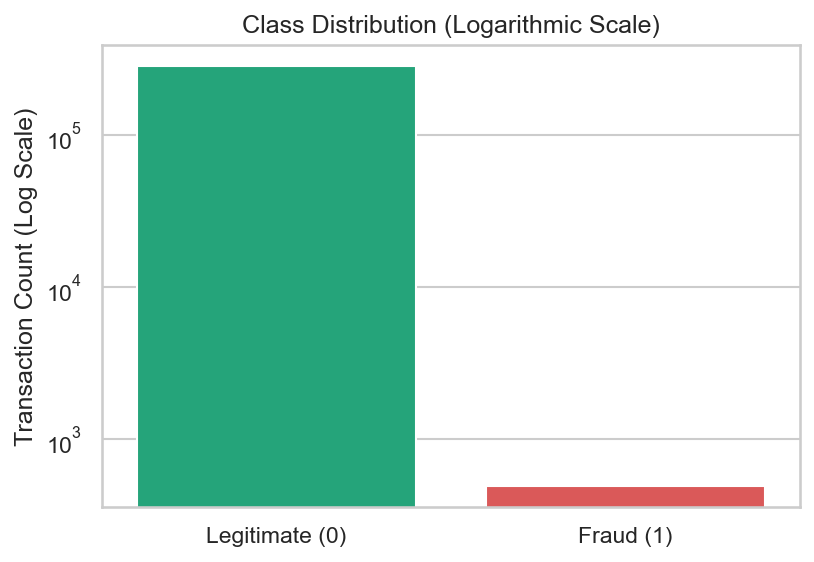

In [2]:
counts = df['Class'].value_counts()
normal_cnt = counts[0]
fraud_cnt = counts[1]
print(f"Normal: {normal_cnt:,} ({normal_cnt/len(df)*100:.4f}%)")
print(f"Fraud: {fraud_cnt:,} ({fraud_cnt/len(df)*100:.4f}%)")

plt.figure(figsize=(6, 4), dpi=150)
sns.barplot(x=['Legitimate (0)', 'Fraud (1)'], y=[normal_cnt, fraud_cnt], palette=['#10B981', '#EF4444'])
plt.yscale('log')
plt.title("Class Distribution (Logarithmic Scale)")
plt.ylabel("Transaction Count (Log Scale)")
plt.show()

## 2. Transaction Amount & Time Distributions

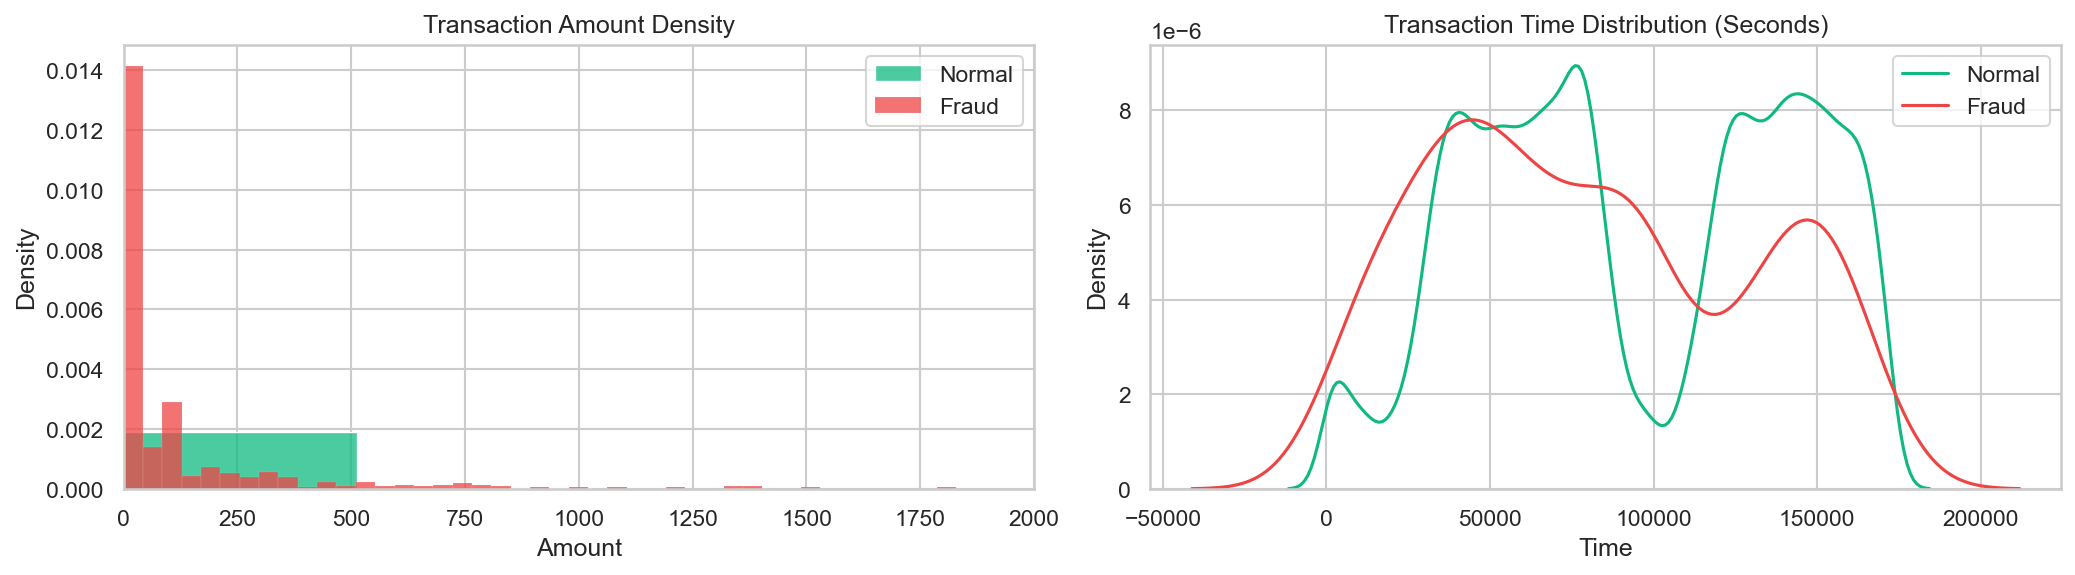

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), dpi=150)

sns.histplot(df[df['Class'] == 0]['Amount'], bins=50, ax=axes[0], color='#10B981', label='Normal', stat='density')
sns.histplot(df[df['Class'] == 1]['Amount'], bins=50, ax=axes[0], color='#EF4444', label='Fraud', stat='density')
axes[0].set_xlim(0, 2000)
axes[0].set_title("Transaction Amount Density")
axes[0].legend()

sns.kdeplot(df[df['Class'] == 0]['Time'], ax=axes[1], color='#10B981', label='Normal')
sns.kdeplot(df[df['Class'] == 1]['Time'], ax=axes[1], color='#EF4444', label='Fraud')
axes[1].set_title("Transaction Time Distribution (Seconds)")
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. PCA Features Correlation with Fraud Target

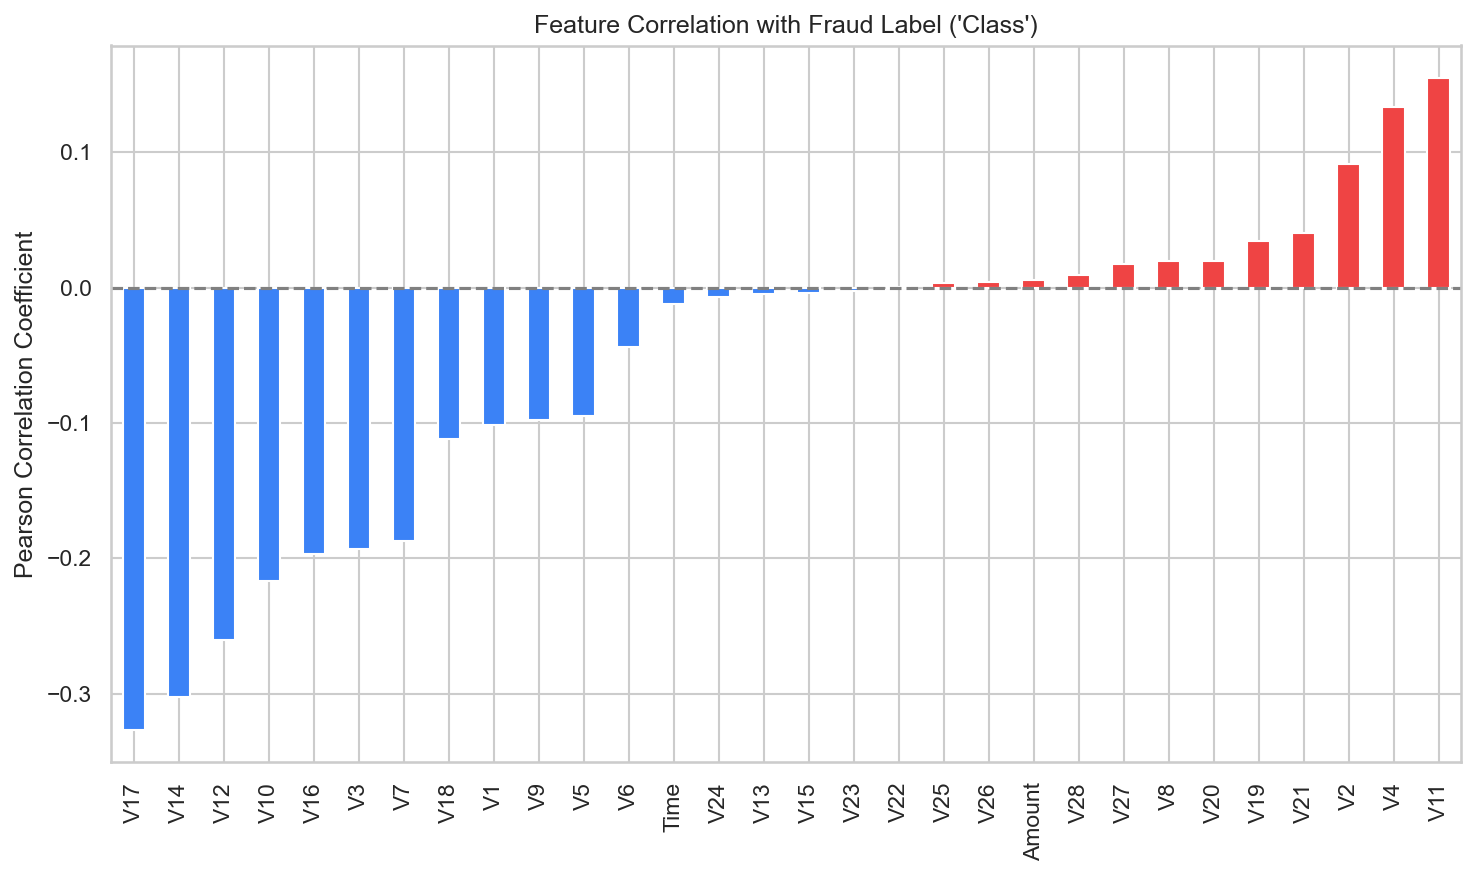

In [4]:
corrs = df.corr()['Class'].drop('Class').sort_values()

plt.figure(figsize=(10, 6), dpi=150)
corrs.plot(kind='bar', color=np.where(corrs > 0, '#EF4444', '#3B82F6'))
plt.title("Feature Correlation with Fraud Label ('Class')")
plt.ylabel("Pearson Correlation Coefficient")
plt.axhline(0, color='gray', linestyle='--')
plt.tight_layout()
plt.show()

## 4. Conclusion & Implications for Autoencoder Architecture

1. **Severe Imbalance**: Because only 0.17% of transactions are fraudulent, traditional supervised classifiers overfit to the majority class or require synthetic oversampling (SMOTE) which can distort high-dimensional PCA manifolds.
2. **Autoencoder Superiority**: By training the Autoencoder strictly on the 99.83% legitimate transactions, the network learns the underlying manifold of legitimate commerce. Anomalies produce naturally high reconstruction errors without requiring balanced training sets.